# Network Intrusion Detection
### Weeks 13–14 Hack-O-Week

Build a machine-learning classifier to identify network connections as **normal** or **attack**. Compare Bagging, Boosting, XGBoost, and LightGBM, and study overfitting, underfitting, bias–variance tradeoff, and L1/L2 regularization.

Dataset: KDD Cup 99 network intrusion dataset from scikit-learn.

In [1]:
%pip -q install xgboost lightgbm

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_kddcup99
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset

In [2]:
data = fetch_kddcup99(percent10=True, random_state=42, download_if_missing=True)
df = pd.DataFrame(data.data, columns=data.feature_names)
df["label"] = data.target

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(lambda x: x.decode("utf-8", errors="ignore") if isinstance(x, bytes) else x)

df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,http,SF,181,5450,0,0,0,0,...,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal.
1,0,tcp,http,SF,239,486,0,0,0,0,...,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal.
2,0,tcp,http,SF,235,1337,0,0,0,0,...,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
3,0,tcp,http,SF,219,1337,0,0,0,0,...,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
4,0,tcp,http,SF,217,2032,0,0,0,0,...,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,normal.


In [3]:
print("Dataset shape:", df.shape)
print("\\nMissing values:", int(df.isnull().sum().sum()))
print("\\nLabel counts:")
print(df["label"].value_counts().head(10))

Dataset shape: (494021, 42)
\nMissing values: 0
\nLabel counts:
label
smurf.          280790
neptune.        107201
normal.          97278
back.             2203
satan.            1589
ipsweep.          1247
portsweep.        1040
warezclient.      1020
teardrop.          979
pod.               264
Name: count, dtype: int64


## 2. Prepare the target and inspect the data

0 = Normal connection
1 = Attack
target
1    396743
0     97278
Name: count, dtype: int64


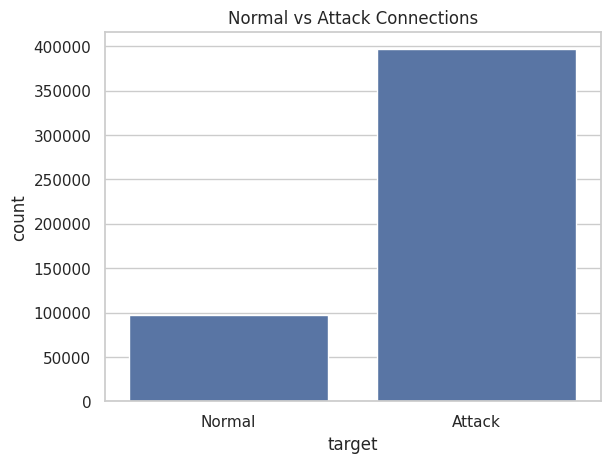

In [4]:
df["target"] = np.where(df["label"] == "normal.", 0, 1)
df = df.drop(columns="label")

print("0 = Normal connection")
print("1 = Attack")
print(df["target"].value_counts())

sns.countplot(data=df, x="target")
plt.xticks([0, 1], ["Normal", "Attack"])
plt.title("Normal vs Attack Connections")
plt.show()

In [5]:
numeric_columns = df.drop(columns="target").select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.drop(columns="target").select_dtypes(exclude=np.number).columns.tolist()

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

Training rows: 395216
Testing rows: 98805
Numeric features: 38
Categorical features: 3


## 3. Preprocessing

In [6]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Processed training shape:", X_train_ready.shape)
print("Processed testing shape:", X_test_ready.shape)

Processed training shape: (395216, 116)
Processed testing shape: (98805, 116)


## 4. Train ensemble models

Bagging trains multiple models on resampled data. Boosting builds models sequentially to improve on earlier errors. XGBoost and LightGBM are gradient-boosting implementations.

In [7]:
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE),
        n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=18, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.0, reg_lambda=1.0,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150, learning_rate=0.1, num_leaves=31,
        reg_alpha=0.0, reg_lambda=1.0,
        random_state=RANDOM_STATE, verbosity=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_ready, y_train)
    pred = model.predict(X_test_ready)
    prob = model.predict_proba(X_test_ready)[:, 1]
    trained_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
4,LightGBM,0.9998,0.9999,0.9998,0.9999,1.0000
3,XGBoost,0.9998,0.9999,0.9998,0.9999,1.0000
2,Random Forest,0.9997,0.9999,0.9998,0.9998,1.0000
0,Bagging,0.9996,0.9999,0.9997,0.9998,1.0000
1,AdaBoost,0.9955,0.9991,0.9953,0.9972,0.9999


## 5. Compare model performance

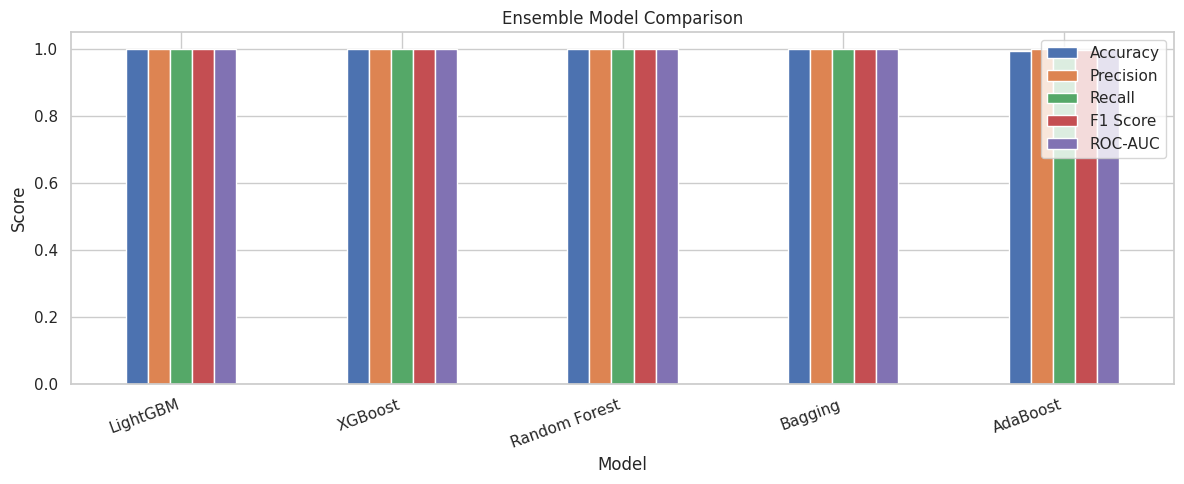

In [8]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1.05)
)
plt.title("Ensemble Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 6. Confusion matrix and classification report

Best model by F1 score: LightGBM
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     19456
      Attack       1.00      1.00      1.00     79349

    accuracy                           1.00     98805
   macro avg       1.00      1.00      1.00     98805
weighted avg       1.00      1.00      1.00     98805



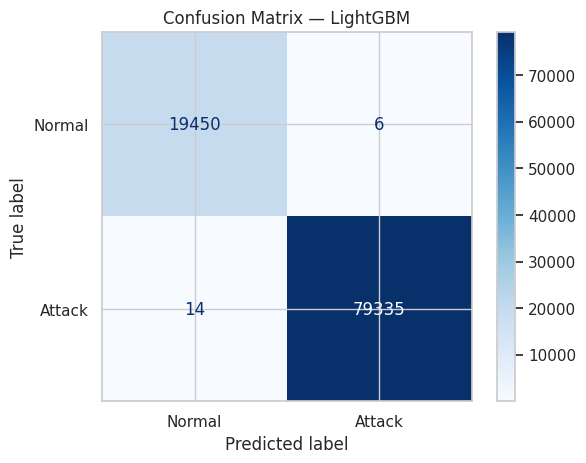

In [9]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test_ready)

print("Best model by F1 score:", best_name)
print(classification_report(
    y_test, best_predictions,
    labels=[0, 1], target_names=["Normal", "Attack"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Normal", "Attack"], cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

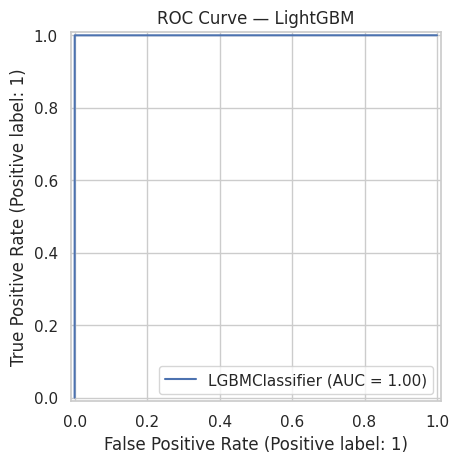

In [10]:
RocCurveDisplay.from_estimator(best_model, X_test_ready, y_test)
plt.title(f"ROC Curve — {best_name}")
plt.show()

## 7. Overfitting and underfitting

A model that performs poorly on both training and test data may be underfitting. A model with very high training performance but noticeably lower test performance may be overfitting.

In [11]:
depths = [1, 2, 4, 8, 16, None]
depth_results = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    tree.fit(X_train_ready, y_train)
    depth_results.append({
        "Max depth": str(depth),
        "Training accuracy": accuracy_score(y_train, tree.predict(X_train_ready)),
        "Testing accuracy": accuracy_score(y_test, tree.predict(X_test_ready))
    })

depth_df = pd.DataFrame(depth_results)
depth_df

,Max depth,Training accuracy,Testing accuracy
0,1,0.979765,0.979961
1,2,0.986767,0.986954
2,4,0.996245,0.995780
3,8,0.999641,0.999504
4,16,0.999924,0.999706
5,None,0.999997,0.999717


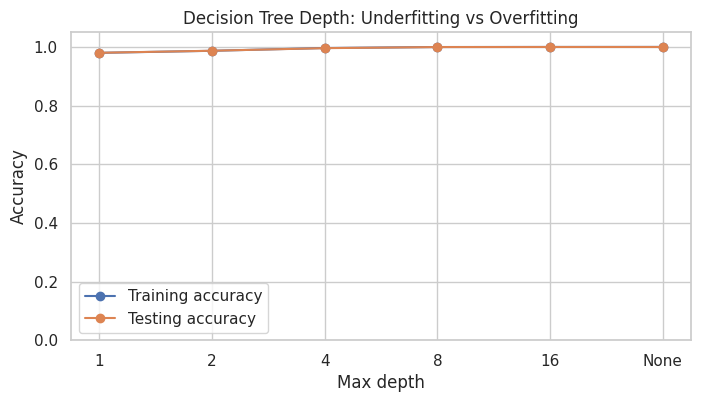

In [12]:
depth_df.set_index("Max depth").plot(marker="o", figsize=(8, 4))
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth: Underfitting vs Overfitting")
plt.show()

## 8. Bias–variance tradeoff

Shallow trees are simpler and may have high bias (underfit). Very deep trees can fit training data closely but may have high variance (overfit). Choosing model complexity balances these effects.

In [13]:
bias_variance_summary = pd.DataFrame({
    "Model complexity": depth_df["Max depth"],
    "Training error": 1 - depth_df["Training accuracy"],
    "Testing error": 1 - depth_df["Testing accuracy"]
})
bias_variance_summary

,Model complexity,Training error,Testing error
0,1,0.020235,0.020039
1,2,0.013233,0.013046
2,4,0.003755,0.004220
3,8,0.000359,0.000496
4,16,0.000076,0.000294
5,None,0.000003,0.000283


## 9. L1 and L2 regularization

L1 regularization (Lasso-style penalty) can push some coefficients to zero. L2 regularization (Ridge-style penalty) shrinks coefficients. Here, Logistic Regression is used to compare L1 and L2 penalties on the same training/test split.

In [14]:
regularized_models = {
    "L1 Logistic Regression": LogisticRegression(
        penalty="l1", solver="saga", C=1.0, max_iter=1500, random_state=RANDOM_STATE
    ),
    "L2 Logistic Regression": LogisticRegression(
        penalty="l2", solver="lbfgs", C=1.0, max_iter=1500, random_state=RANDOM_STATE
    )
}

regularization_results = []

for name, model in regularized_models.items():
    model.fit(X_train_ready, y_train)
    pred = model.predict(X_test_ready)
    regularization_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

pd.DataFrame(regularization_results).round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,L1 Logistic Regression,0.9974,0.9990,0.9977,0.9984
1,L2 Logistic Regression,0.9985,0.9992,0.9989,0.9990


## 10. Regularization strength

In Logistic Regression, smaller `C` means stronger regularization. This experiment compares L2 models with different strengths.

In [15]:
c_values = [0.01, 0.1, 1, 10, 100]
c_results = []

for c in c_values:
    model = LogisticRegression(
        penalty="l2", C=c, max_iter=1500, random_state=RANDOM_STATE
    )
    model.fit(X_train_ready, y_train)
    c_results.append({
        "C": c,
        "Training accuracy": accuracy_score(y_train, model.predict(X_train_ready)),
        "Testing accuracy": accuracy_score(y_test, model.predict(X_test_ready))
    })

c_df = pd.DataFrame(c_results)
c_df

,C,Training accuracy,Testing accuracy
0,0.01,0.997867,0.997581
1,0.10,0.998434,0.998269
2,1.00,0.998667,0.998451
3,10.00,0.998730,0.998543
4,100.00,0.998750,0.998563


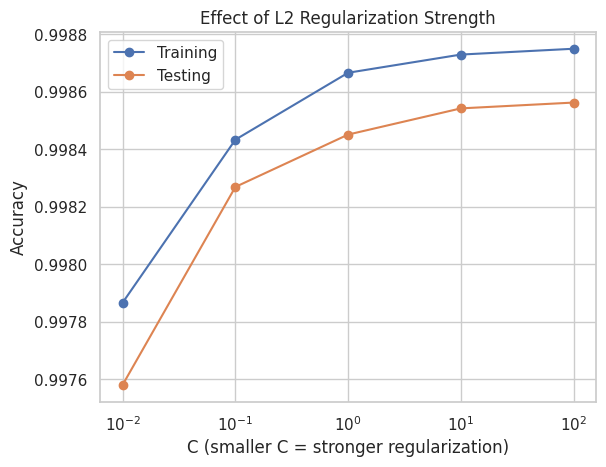

In [16]:
plt.plot(c_df["C"], c_df["Training accuracy"], marker="o", label="Training")
plt.plot(c_df["C"], c_df["Testing accuracy"], marker="o", label="Testing")
plt.xscale("log")
plt.xlabel("C (smaller C = stronger regularization)")
plt.ylabel("Accuracy")
plt.title("Effect of L2 Regularization Strength")
plt.legend()
plt.show()

## Conclusion
This project compares Bagging, AdaBoost, Random Forest, XGBoost, and LightGBM for binary network intrusion detection. It evaluates accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices, then demonstrates tree-depth effects, the bias–variance tradeoff, and L1/L2 regularization. The KDD Cup 99 dataset is a historical benchmark, so the results should not be treated as proof of performance on modern network traffic.